In [38]:
import os
import re
import ast
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/ted_recommendation_data.csv')
df = df.reset_index(drop=True)
print("Dataset loaded successfully. Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully. Shape: (4005, 8)


In [40]:
def parse_topics(value):
    if isinstance(value, list):
        return {str(x).strip().lower() for x in value if str(x).strip()}
    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, list):
            return {str(x).strip().lower() for x in parsed if str(x).strip()}
    except (ValueError, SyntaxError):
        pass
    return set()

def clean_topics_to_string(value):
    topics_list = parse_topics(value)
    return " ".join(topics_list)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)  # Remove HTML tags
    text = re.sub(r"http\S+|www\S+", " ", text)  # Remove URLs
    text = re.sub(r"[^a-z0-9\s]", " ", text)  # Remove special characters
    text = re.sub(r"\s+", " ", text).strip()  # Extra spaces
    return text

# Apply preprocessing
df["topics_list"] = df["topics"].apply(parse_topics)
df["topics_clean"] = df["topics"].apply(clean_topics_to_string)

for col in ["title", "description", "transcript"]:
    df[col + "_clean"] = df[col].fillna("").astype(str).apply(preprocess_text)

df["content_clean"] = (
    df["title_clean"] + " " +
    df["topics_clean"] + " " +
    df["description_clean"] + " " +
    df["transcript_clean"]
)

display(df[["title", "topics_clean", "content_clean"]].head(3))

,title,topics_clean,content_clean
0,Averting the climate crisis,sustainability global issues science culture c...,averting the climate crisis sustainability glo...
1,The best stats you've ever seen,statistics google global development global is...,the best stats you ve ever seen statistics goo...
2,Simplicity sells,media performance software music computers ent...,simplicity sells media performance software mu...


In [42]:
def create_vectorizer():
    return TfidfVectorizer(
        stop_words="english",
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        dtype=np.float32
    )

title_vectorizer = create_vectorizer()
topics_vectorizer = create_vectorizer()
description_vectorizer = create_vectorizer()
transcript_vectorizer = create_vectorizer()

title_matrix = title_vectorizer.fit_transform(df["title_clean"])
topics_matrix = topics_vectorizer.fit_transform(df["topics_clean"])
description_matrix = description_vectorizer.fit_transform(df["description_clean"])
transcript_matrix = transcript_vectorizer.fit_transform(df["transcript_clean"])

print("Title matrix shape:", title_matrix.shape)
print("Topics matrix shape:", topics_matrix.shape)
print("Description matrix shape:", description_matrix.shape)
print("Transcript matrix shape:", transcript_matrix.shape)

Title matrix shape: (4005, 2515)
Topics matrix shape: (4005, 4545)
Description matrix shape: (4005, 10000)
Transcript matrix shape: (4005, 10000)


In [43]:
def recommend_hybrid(talk_id, top_n=5):
    matches = df.index[df["talk_id"] == talk_id].tolist()
    if not matches:
        print("Talk not found.")
        return None
    talk_idx = matches[0]

    # Component similarities
    s_title = cosine_similarity(title_matrix[talk_idx], title_matrix).ravel()
    s_topics = cosine_similarity(topics_matrix[talk_idx], topics_matrix).ravel()
    s_desc = cosine_similarity(description_matrix[talk_idx], description_matrix).ravel()
    s_trans = cosine_similarity(transcript_matrix[talk_idx], transcript_matrix).ravel()

    # Weighted composition
    hybrid_scores = 0.30 * s_title + 0.35 * s_topics + 0.25 * s_desc + 0.10 * s_trans
    hybrid_scores[talk_idx] = -1.0  # Exclude target

    top_indices = np.argsort(hybrid_scores)[::-1][:top_n]
    results = df.loc[top_indices, ["talk_id", "title", "speaker_1", "url", "views"]].copy()
    results["similarity_score"] = hybrid_scores[top_indices]
    return results.reset_index(drop=True)

In [45]:
def build_ground_truth(topic_sets, min_overlap=2):
    relevance_maps = {}
    for i, topics_a in enumerate(topic_sets):
        if not topics_a:
            continue
        relevant = {}
        for j, topics_b in enumerate(topic_sets):
            if i == j or not topics_b:
                continue
            intersection = topics_a & topics_b
            union = topics_a | topics_b
            overlap = len(intersection)
            jaccard = len(intersection) / len(union) if union else 0.0

            if overlap >= min_overlap or jaccard >= 0.25:
                if jaccard >= 0.50 or overlap >= 4:
                    relevance = 3
                elif jaccard >= 0.33 or overlap >= 3:
                    relevance = 2
                else:
                    relevance = 1
                relevant[j] = relevance
        if len(relevant) >= 5:
            relevance_maps[i] = relevant
    return relevance_maps

topic_sets = df["topics_list"].tolist()
relevance_maps = build_ground_truth(topic_sets)

In [46]:
def precision_at_k(rec, rel, k=5):
    return sum(1 for x in rec[:k] if x in rel) / k

def recall_at_k(rec, rel, k=5):
    return sum(1 for x in rec[:k] if x in rel) / len(rel) if rel else 0.0

def average_precision_at_k(rec, rel, k=5):
    if not rel: return 0.0
    score, hits = 0.0, 0
    for rank, item in enumerate(rec[:k], start=1):
        if item in rel:
            hits += 1
            score += hits / rank
    return score / min(len(rel), k)

def ndcg_at_k(rec, rel, k=5):
    gains = [rel.get(item, 0) for item in rec[:k]]
    dcg = sum((2 ** gain - 1) / np.log2(rank + 1) for rank, gain in enumerate(gains, start=1))
    ideal_gains = sorted(rel.values(), reverse=True)[:k]
    idcg = sum((2 ** gain - 1) / np.log2(rank + 1) for rank, gain in enumerate(ideal_gains, start=1))
    return dcg / idcg if idcg > 0 else 0.0

In [48]:
full_vectorizer = create_vectorizer()
full_content_matrix = full_vectorizer.fit_transform(df["content_clean"].fillna(""))

def get_model_scores(query_idx):
    target_topics = topic_sets[query_idx]
    jaccard_scores = np.array([
        len(target_topics & current_topics) / len(target_topics | current_topics)
        if target_topics | current_topics else 0.0
        for current_topics in topic_sets
    ])

    s_title = cosine_similarity(title_matrix[query_idx], title_matrix).ravel()
    s_topics = cosine_similarity(topics_matrix[query_idx], topics_matrix).ravel()
    s_desc = cosine_similarity(description_matrix[query_idx], description_matrix).ravel()
    s_trans = cosine_similarity(transcript_matrix[query_idx], transcript_matrix).ravel()

    metadata_scores = (s_title + s_topics + s_desc) / 3
    full_scores = cosine_similarity(full_content_matrix[query_idx], full_content_matrix).ravel()
    hybrid_scores = 0.30 * s_title + 0.35 * s_topics + 0.25 * s_desc + 0.10 * s_trans

    score_map = {
        "Jaccard Topic Baseline": jaccard_scores,
        "Metadata TF-IDF": metadata_scores,
        "Full-Content TF-IDF": full_scores,
        "Weighted Hybrid TF-IDF": hybrid_scores
    }
    for scores in score_map.values():
        scores[query_idx] = -1.0
    return score_map

In [49]:
def evaluate_models(k=5, sample_size=250, seed=42):
    rng = np.random.default_rng(seed)
    available_queries = list(relevance_maps.keys())
    eval_indices = rng.choice(available_queries, size=min(sample_size, len(available_queries)), replace=False)

    model_names = ["Jaccard Topic Baseline", "Metadata TF-IDF", "Full-Content TF-IDF", "Weighted Hybrid TF-IDF"]
    results = {model: {"Precision": [], "Recall": [], "NDCG": [], "MAP": []} for model in model_names}

    for query_idx in eval_indices:
        relevant = relevance_maps[query_idx]
        score_map = get_model_scores(query_idx)
        for model_name, scores in score_map.items():
            recommended = np.argsort(scores)[::-1][:k]
            results[model_name]["Precision"].append(precision_at_k(recommended, relevant, k))
            results[model_name]["Recall"].append(recall_at_k(recommended, relevant, k))
            results[model_name]["NDCG"].append(ndcg_at_k(recommended, relevant, k))
            results[model_name]["MAP"].append(average_precision_at_k(recommended, relevant, k))

    rows = []
    for model_name in model_names:
        rows.append({
            "Model": model_name,
            f"Precision@{k}": np.mean(results[model_name]["Precision"]),
            f"Recall@{k}": np.mean(results[model_name]["Recall"]),
            f"NDCG@{k}": np.mean(results[model_name]["NDCG"]),
            f"MAP@{k}": np.mean(results[model_name]["MAP"])
        })
    return pd.DataFrame(rows), results, eval_indices

evaluation_df, evaluation_details, evaluated_queries = evaluate_models(k=5, sample_size=250)
evaluation_df["Overall Score"] = evaluation_df[[f"Precision@5", f"Recall@5", f"NDCG@5", f"MAP@5"]].mean(axis=1)
evaluation_df = evaluation_df.sort_values(by="Overall Score", ascending=False).reset_index(drop=True)
display(evaluation_df)

,Model,Precision@5,Recall@5,NDCG@5,MAP@5,Overall Score
0,Jaccard Topic Baseline,1.0000,0.029921,0.916532,1.000000,0.736613
1,Weighted Hybrid TF-IDF,0.7960,0.019202,0.574948,0.744907,0.533764
2,Metadata TF-IDF,0.7448,0.017848,0.520289,0.684960,0.491974
3,Full-Content TF-IDF,0.7168,0.014714,0.449687,0.650173,0.457844


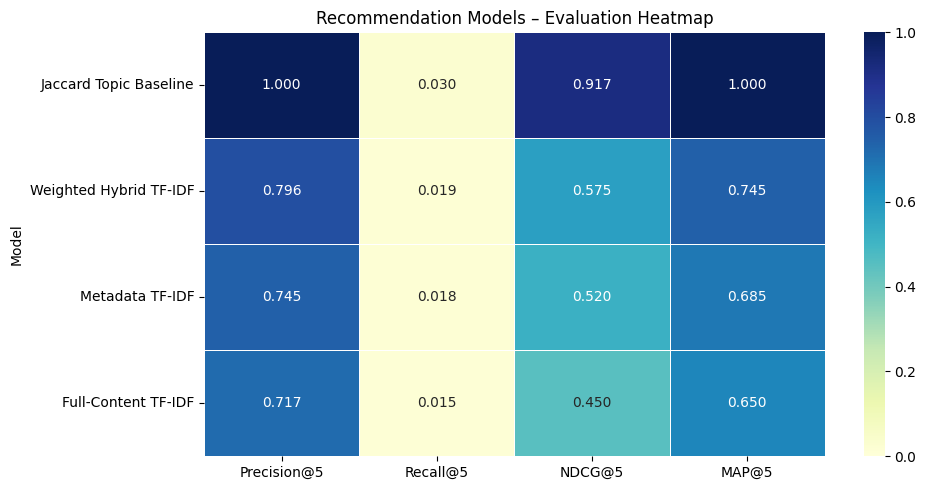

In [51]:
# Plot overall comparison
plt.figure(figsize=(10, 5))
plot_df = evaluation_df.set_index("Model")[["Precision@5", "Recall@5", "NDCG@5", "MAP@5"]]
sns.heatmap(plot_df, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=0.5, vmin=0, vmax=1)
plt.title("Recommendation Models – Evaluation Heatmap")
plt.tight_layout()
plt.savefig("model_evaluation_heatmap.png", dpi=300)
plt.show()

In [52]:
# Save finalized artifacts to Drive
save_dir = '/content/drive/MyDrive/ted_recommendation_models/'
os.makedirs(save_dir, exist_ok=True)

# 1. Save Vectorizers
vectorizers = {
    'title_vectorizer': title_vectorizer,
    'topics_vectorizer': topics_vectorizer,
    'description_vectorizer': description_vectorizer,
    'transcript_vectorizer': transcript_vectorizer
}
with open(os.path.join(save_dir, 'vectorizers.pkl'), 'wb') as f:
    pickle.dump(vectorizers, f)

# 2. Save TF-IDF Matrices
matrices = {
    'title_matrix': title_matrix,
    'topics_matrix': topics_matrix,
    'description_matrix': description_matrix,
    'transcript_matrix': transcript_matrix
}
with open(os.path.join(save_dir, 'tfidf_matrices.pkl'), 'wb') as f:
    pickle.dump(matrices, f)

# 3. Save Cleaned DataFrame
df.to_pickle(os.path.join(save_dir, 'cleaned_df.pkl'))

evaluation_df.to_csv("ted_recommendation_evaluation.csv", index=False)
print("All structures, clean models and evaluations saved to Drive successfully.")

All structures, clean models and evaluations saved to Drive successfully.


In [ ]:
def compare_models(talk_id, top_n=5):

    models = {
        "Full-content TF-IDF": recommend_talks,
        "Metadata TF-IDF": recommend_talks_high_similarity,
        "Jaccard": recommend_jaccard,
        "Weighted Hybrid TF-IDF": recommend_hybrid
    }

    comparison = {}

    for model_name, model_func in models.items():

        result = model_func(
            talk_id,
            top_n=top_n
        )

        comparison[model_name] = result

        print("\n", "=" * 60)
        print(model_name)
        print("=" * 60)

        if result is not None:
            display(
                result[[
                    "title",
                    "speaker_1",
                    "similarity_score"
                ]]
            )

    return comparison

In [ ]:
def parse_topic_list(value):

    if isinstance(value, list):
        return {
            str(x).strip().lower()
            for x in value
            if str(x).strip()
        }

    try:
        parsed = ast.literal_eval(str(value))

        if isinstance(parsed, list):
            return {
                str(x).strip().lower()
                for x in parsed
                if str(x).strip()
            }

    except (ValueError, SyntaxError):
        pass

    return set()


df["topics_list"] = df["topics"].apply(
    parse_topic_list
)


def recommend_jaccard(talk_id, top_n=5):

    matches = df.index[
        df["talk_id"] == talk_id
    ].tolist()

    if not matches:
        print("Talk not found.")
        return None

    talk_idx = matches[0]

    target_topics = df.loc[
        talk_idx, "topics_list"
    ]

    scores = []

    for idx, row in df.iterrows():

        if idx == talk_idx:
            scores.append(-1.0)
            continue

        current_topics = row["topics_list"]

        union = target_topics | current_topics
        intersection = target_topics & current_topics

        score = (
            len(intersection) / len(union)
            if union else 0.0
        )

        scores.append(score)

    scores = np.array(scores)

    top_indices = np.argsort(
        scores
    )[::-1][:top_n]

    results = df.loc[
        top_indices,
        ["talk_id", "title", "speaker_1", "url"]
    ].copy()

    results["similarity_score"] = (
        scores[top_indices]
    )

    return results.reset_index(drop=True)

In [ ]:
def compare_models(talk_id, top_n=5):

    models = {
        "Full-content TF-IDF": recommend_talks,
        "Metadata TF-IDF": recommend_talks_high_similarity,
        "Jaccard": recommend_jaccard,
        "Weighted Hybrid TF-IDF": recommend_hybrid
    }

    comparison = {}

    for model_name, model_func in models.items():

        result = model_func(
            talk_id,
            top_n=top_n
        )

        comparison[model_name] = result

        print("\n", "=" * 60)
        print(model_name)
        print("=" * 60)

        if result is not None:
            display(
                result[[
                    "title",
                    "speaker_1",
                    "similarity_score"
                ]]
            )

    return comparison

In [ ]:
def precision_at_k(recommended_ids, relevant_ids, k=5):

    recommended = set(recommended_ids[:k])
    relevant = set(relevant_ids)

    if not recommended:
        return 0.0

    return len(recommended & relevant) / k

In [ ]:
metadata_columns = [
    "talk_id",
    "title",
    "speaker_1",
    "topics",
    "description",
    "url",
    "views"
]

metadata = df[metadata_columns].copy()

metadata.to_csv(
    "/content/drive/MyDrive/ted_talk_metadata.csv",
    index=False
)

print("Metadata saved successfully!")
print(metadata.shape)

Metadata saved successfully!
(4005, 7)


In [ ]:
print("Metadata shape:", metadata.shape)

print("\nColumns:")
print(metadata.columns.tolist())

print("\nMissing values:")
print(metadata.isnull().sum())

display(metadata.head())

Metadata shape: (4005, 7)

Columns:
['talk_id', 'title', 'speaker_1', 'topics', 'description', 'url', 'views']

Missing values:
talk_id        0
title          0
speaker_1      0
topics         0
description    0
url            0
views          0
dtype: int64


,talk_id,title,speaker_1,topics,description,url,views
0,1,Averting the climate crisis,Al Gore,"['alternative energy', 'cars', 'climate change...",With the same humor and humanity he exuded in ...,https://www.ted.com/talks/al_gore_averting_the...,3523392
1,92,The best stats you've ever seen,Hans Rosling,"['Africa', 'Asia', 'Google', 'demo', 'economic...",You've never seen data presented like this. Wi...,https://www.ted.com/talks/hans_rosling_the_bes...,14501685
2,7,Simplicity sells,David Pogue,"['computers', 'entertainment', 'interface desi...",New York Times columnist David Pogue takes aim...,https://www.ted.com/talks/david_pogue_simplici...,1920832
3,53,Greening the ghetto,Majora Carter,"['MacArthur grant', 'activism', 'business', 'c...","In an emotionally charged talk, MacArthur-winn...",https://www.ted.com/talks/majora_carter_greeni...,2664069
4,66,Do schools kill creativity?,Sir Ken Robinson,"['children', 'creativity', 'culture', 'dance',...",Sir Ken Robinson makes an entertaining and pro...,https://www.ted.com/talks/sir_ken_robinson_do_...,65051954


In [ ]:
def create_vectorizer():
    return TfidfVectorizer(
        stop_words="english",
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        dtype=np.float32
    )

title_vectorizer = create_vectorizer()
topics_vectorizer = create_vectorizer()
description_vectorizer = create_vectorizer()
transcript_vectorizer = create_vectorizer()

title_matrix = title_vectorizer.fit_transform(
    df["title_clean"]
)

topics_matrix = topics_vectorizer.fit_transform(
    df["topics_clean"]
)

description_matrix = description_vectorizer.fit_transform(
    df["description_clean"]
)

transcript_matrix = transcript_vectorizer.fit_transform(
    df["transcript_clean"]
)

print(title_matrix.shape)
print(topics_matrix.shape)
print(description_matrix.shape)
print(transcript_matrix.shape)

(4005, 2515)
(4005, 4977)
(4005, 10000)
(4005, 10000)


In [ ]:
import pickle
import os

# Define the directory to save models
save_dir = '/content/drive/MyDrive/ted_recommendation_models/'
os.makedirs(save_dir, exist_ok=True)

# 1. Save the Vectorizers
vectorizers = {
    'title_vectorizer': title_vectorizer,
    'topics_vectorizer': topics_vectorizer,
    'description_vectorizer': description_vectorizer,
    'transcript_vectorizer': transcript_vectorizer
}

with open(os.path.join(save_dir, 'vectorizers.pkl'), 'wb') as f:
    pickle.dump(vectorizers, f)

# 2. Save the TF-IDF Matrices
matrices = {
    'title_matrix': title_matrix,
    'topics_matrix': topics_matrix,
    'description_matrix': description_matrix,
    'transcript_matrix': transcript_matrix
}

with open(os.path.join(save_dir, 'tfidf_matrices.pkl'), 'wb') as f:
    pickle.dump(matrices, f)

# 3. Save the Cleaned DataFrame
df.to_pickle(os.path.join(save_dir, 'cleaned_df.pkl'))

print("All models, matrices, and DataFrames saved successfully to:", save_dir)

All models, matrices, and DataFrames saved successfully to: /content/drive/MyDrive/ted_recommendation_models/


### How to Load the Saved Models later:

When you return to this notebook or start a new session, you can load everything back using the following template:

```python
import pickle
import os

save_dir = '/content/drive/MyDrive/ted_recommendation_models/'

# Load the DataFrame
df = pd.read_pickle(os.path.join(save_dir, 'cleaned_df.pkl'))

# Load Vectorizers
with open(os.path.join(save_dir, 'vectorizers.pkl'), 'rb') as f:
    vectorizers = pickle.load(f)
title_vectorizer = vectorizers['title_vectorizer']
topics_vectorizer = vectorizers['topics_vectorizer']
description_vectorizer = vectorizers['description_vectorizer']
transcript_vectorizer = vectorizers['transcript_vectorizer']

# Load Matrices
with open(os.path.join(save_dir, 'tfidf_matrices.pkl'), 'rb') as f:
    matrices = pickle.load(f)
title_matrix = matrices['title_matrix']
topics_matrix = matrices['topics_matrix']
description_matrix = matrices['description_matrix']
transcript_matrix = matrices['transcript_matrix']
```


=== Offline Evaluation Report (K=5, Queries=250) ===
                  Model  Precision@5  Recall@5  NDCG@5  MAP@5
 Jaccard Topic Baseline       1.0000    0.0299  0.9165 1.0000
Metadata TF-IDF (Equal)       0.7320    0.0176  0.4971 0.6691
    Full-Content TF-IDF       0.6120    0.0125  0.3510 0.5293
 Weighted Hybrid TF-IDF       0.7912    0.0191  0.5575 0.7351

Saved visualization to model_evaluation_comparison.png


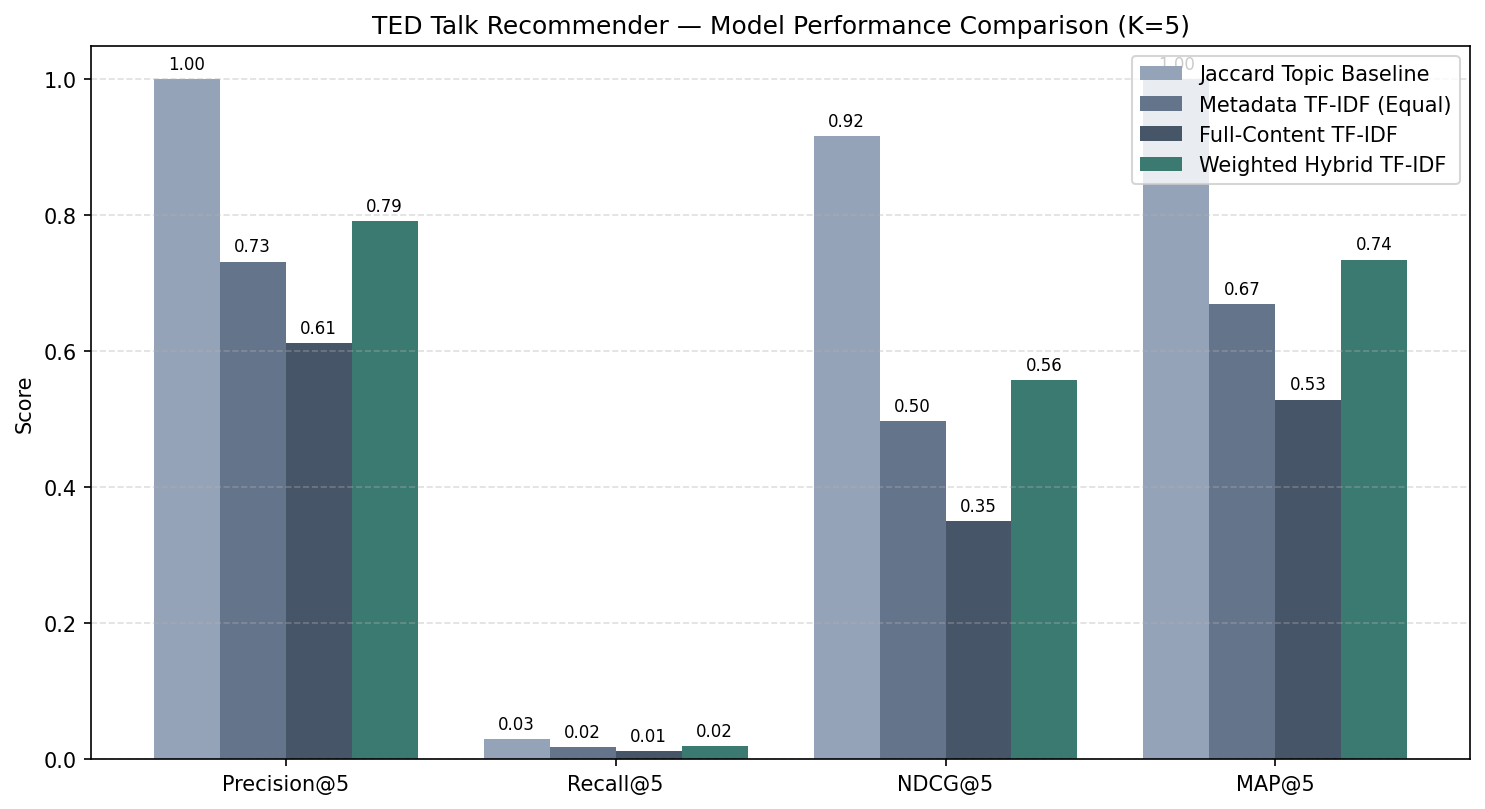

In [ ]:
import ast
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer


def parse_topics(val):
    if isinstance(val, list):
        return set(str(t).strip().lower() for t in val if str(t).strip())
    if isinstance(val, str):
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, list):
                return set(str(t).strip().lower() for t in parsed if str(t).strip())
        except (ValueError, SyntaxError):
            pass
        cleaned = val.strip("[]'\"")
        return set(t.strip().strip("'\"").lower() for t in cleaned.split(",") if t.strip())
    return set()


def build_ground_truth(df, topic_sets, min_overlap=2):
    """
    Constructs binary and graded relevance dictionaries for each talk
    based on thematic topic overlap.
    """
    n = len(df)
    relevance_maps = {}
    for i in range(n):
        t_q = topic_sets[i]
        if not t_q:
            continue
        rel_dict = {}
        for j in range(n):
            if i == j or not topic_sets[j]:
                continue
            overlap = len(t_q & topic_sets[j])
            union = len(t_q | topic_sets[j])
            jaccard = overlap / union if union > 0 else 0.0
            if overlap >= min_overlap or jaccard >= 0.25:
                # Graded relevance: 3 (strong match), 2 (moderate), 1 (minimal)
                if jaccard >= 0.50 or overlap >= 4:
                    rel_dict[j] = 3
                elif jaccard >= 0.33 or overlap >= 3:
                    rel_dict[j] = 2
                else:
                    rel_dict[j] = 1
        if len(rel_dict) >= 5:
            relevance_maps[i] = rel_dict
    return relevance_maps


def compute_ranking_metrics(recommended_indices, rel_dict, k=5):
    top_k = recommended_indices[:k]
    total_relevant = len(rel_dict)
    if total_relevant == 0:
        return 0.0, 0.0, 0.0, 0.0

    # Binary hits & graded gains
    hits = [1 if idx in rel_dict else 0 for idx in top_k]
    gains = [rel_dict.get(idx, 0) for idx in top_k]

    # Precision@K & Recall@K
    precision = sum(hits) / k
    recall = sum(hits) / total_relevant

    # Average Precision@K
    cum_hits = 0
    ap_sum = 0.0
    for rank, hit in enumerate(hits, start=1):
        if hit:
            cum_hits += 1
            ap_sum += cum_hits / rank
    ap = ap_sum / min(k, total_relevant)

    # NDCG@K
    dcg = sum((2**rel - 1) / np.log2(rank + 1) for rank, rel in enumerate(gains, start=1))
    ideal_gains = sorted(rel_dict.values(), reverse=True)[:k]
    idcg = sum((2**rel - 1) / np.log2(rank + 1) for rank, rel in enumerate(ideal_gains, start=1))
    ndcg = dcg / idcg if idcg > 0 else 0.0

    return precision, recall, ndcg, ap


def evaluate_all_models(df_path="cleaned_df.pkl", mat_path="tfidf_matrices.pkl", k=5, sample_size=250, seed=42):
    df = pd.read_pickle(df_path)
    with open(mat_path, "rb") as f:
        matrices = pickle.load(f)

    title_mat = matrices["title_matrix"]
    topics_mat = matrices["topics_matrix"]
    desc_mat = matrices["description_matrix"]
    trans_mat = matrices["transcript_matrix"]

    # Build Full-Content TF-IDF matrix for baseline comparison
    combined_text = (
        df["title"].fillna("") + " " +
        df["topics"].astype(str).fillna("") + " " +
        df["description"].fillna("") + " " +
        df.get("transcript", pd.Series([""] * len(df))).fillna("")
    )
    full_tfidf_mat = TfidfVectorizer(max_features=10000, stop_words="english").fit_transform(combined_text)

    topic_sets = [parse_topics(t) for t in df["topics"]]
    rel_maps = build_ground_truth(df, topic_sets)

    rng = np.random.default_rng(seed)
    eval_indices = rng.choice(list(rel_maps.keys()), size=min(sample_size, len(rel_maps)), replace=False)

    models = [
        "Jaccard Topic Baseline",
        "Metadata TF-IDF (Equal)",
        "Full-Content TF-IDF",
        "Weighted Hybrid TF-IDF"
    ]
    results = {m: {"Precision": [], "Recall": [], "NDCG": [], "MAP": []} for m in models}

    for idx in eval_indices:
        rel_dict = rel_maps[idx]

        # 1. Jaccard Similarity
        t_q = topic_sets[idx]
        j_scores = np.array([
            len(t_q & t_j) / len(t_q | t_j) if len(t_q | t_j) > 0 else 0.0
            for t_j in topic_sets
        ])
        j_scores[idx] = -1.0

        # Precompute component cosine similarities
        s_title = cosine_similarity(title_mat[idx], title_mat).ravel()
        s_topics = cosine_similarity(topics_mat[idx], topics_mat).ravel()
        s_desc = cosine_similarity(desc_mat[idx], desc_mat).ravel()
        s_trans = cosine_similarity(trans_mat[idx], trans_mat).ravel()

        # 2. Metadata TF-IDF (Equal weights on Title, Topics, Description)
        meta_scores = (s_title + s_topics + s_desc) / 3.0
        meta_scores[idx] = -1.0

        # 3. Full-Content TF-IDF (Single concatenated corpus)
        full_scores = cosine_similarity(full_tfidf_mat[idx], full_tfidf_mat).ravel()
        full_scores[idx] = -1.0

        # 4. Weighted Hybrid TF-IDF (Production Model: 30/35/25/10)
        hybrid_scores = 0.30 * s_title + 0.35 * s_topics + 0.25 * s_desc + 0.10 * s_trans
        hybrid_scores[idx] = -1.0

        score_map = {
            "Jaccard Topic Baseline": j_scores,
            "Metadata TF-IDF (Equal)": meta_scores,
            "Full-Content TF-IDF": full_scores,
            "Weighted Hybrid TF-IDF": hybrid_scores,
        }

        for m_name, scores in score_map.items():
            top_k_idx = np.argsort(scores)[::-1][:k]
            p, r, ndcg, ap = compute_ranking_metrics(top_k_idx, rel_dict, k=k)
            results[m_name]["Precision"].append(p)
            results[m_name]["Recall"].append(r)
            results[m_name]["NDCG"].append(ndcg)
            results[m_name]["MAP"].append(ap)

    summary_rows = []
    for m_name in models:
        summary_rows.append({
            "Model": m_name,
            f"Precision@{k}": np.mean(results[m_name]["Precision"]),
            f"Recall@{k}": np.mean(results[m_name]["Recall"]),
            f"NDCG@{k}": np.mean(results[m_name]["NDCG"]),
            f"MAP@{k}": np.mean(results[m_name]["MAP"]),
        })

    summary_df = pd.DataFrame(summary_rows)
    print(f"\n=== Offline Evaluation Report (K={k}, Queries={len(eval_indices)}) ===")
    print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    # Plot grouped bar comparison
    metrics = [f"Precision@{k}", f"Recall@{k}", f"NDCG@{k}", f"MAP@{k}"]
    x = np.arange(len(metrics))
    width = 0.20
    colors = ["#94A3B8", "#64748B", "#475569", "#3B7A70"]

    fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
    for i, m_name in enumerate(models):
        vals = [summary_df.loc[i, m] for m in metrics]
        bars = ax.bar(x + (i - 1.5) * width, vals, width, label=m_name, color=colors[i])
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.2f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

    ax.set_ylabel("Score")
    ax.set_title(f"TED Talk Recommender — Model Performance Comparison (K={k})")
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(frameon=True, facecolor="white")
    plt.tight_layout()
    plt.savefig("model_evaluation_comparison.png")
    print("\nSaved visualization to model_evaluation_comparison.png")


if __name__ == "__main__":
    # Use the correct paths mapping to Google Drive to avoid FileNotFoundError
    import os
    save_dir = '/content/drive/MyDrive/ted_recommendation_models/'
    df_path = os.path.join(save_dir, 'cleaned_df.pkl')
    mat_path = os.path.join(save_dir, 'tfidf_matrices.pkl')
    evaluate_all_models(df_path=df_path, mat_path=mat_path, k=5)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from IPython.display import display

# Ensure consistent indexing
df = df.reset_index(drop=True)

# Parse TED topics
def parse_topics(value):

    if isinstance(value, list):
        return {
            str(x).strip().lower()
            for x in value if str(x).strip()
        }

    try:
        parsed = ast.literal_eval(str(value))

        if isinstance(parsed, list):
            return {
                str(x).strip().lower()
                for x in parsed if str(x).strip()
            }

    except (ValueError, SyntaxError):
        pass

    return set()


df["topics_list"] = df["topics"].apply(parse_topics)

topic_sets = df["topics_list"].tolist()

print("Dataset shape:", df.shape)
print("Topic sets prepared:", len(topic_sets))

Dataset shape: (4005, 15)
Topic sets prepared: 4005


In [ ]:
def build_ground_truth(topic_sets, min_overlap=2):

    relevance_maps = {}

    for i, topics_a in enumerate(topic_sets):

        if not topics_a:
            continue

        relevant = {}

        for j, topics_b in enumerate(topic_sets):

            if i == j or not topics_b:
                continue

            intersection = topics_a & topics_b
            union = topics_a | topics_b

            overlap = len(intersection)
            jaccard = len(intersection) / len(union)

            if overlap >= min_overlap or jaccard >= 0.25:

                if jaccard >= 0.50 or overlap >= 4:
                    relevance = 3

                elif jaccard >= 0.33 or overlap >= 3:
                    relevance = 2

                else:
                    relevance = 1

                relevant[j] = relevance

        if len(relevant) >= 5:
            relevance_maps[i] = relevant

    return relevance_maps


relevance_maps = build_ground_truth(topic_sets)

print("Eligible evaluation queries:", len(relevance_maps))
print("Ground truth generated successfully!")

Eligible evaluation queries: 4001
Ground truth generated successfully!


In [ ]:
def precision_at_k(recommended, relevant, k=5):

    hits = sum(1 for x in recommended[:k] if x in relevant)

    return hits / k


def recall_at_k(recommended, relevant, k=5):

    if not relevant:
        return 0.0

    hits = sum(1 for x in recommended[:k] if x in relevant)

    return hits / len(relevant)


def average_precision_at_k(recommended, relevant, k=5):

    if not relevant:
        return 0.0

    score = 0.0
    hits = 0

    for rank, item in enumerate(recommended[:k], start=1):

        if item in relevant:

            hits += 1
            score += hits / rank

    return score / min(len(relevant), k)


def ndcg_at_k(recommended, relevant, k=5):

    gains = [
        relevant.get(item, 0)
        for item in recommended[:k]
    ]

    dcg = sum(
        (2 ** gain - 1) / np.log2(rank + 1)
        for rank, gain in enumerate(gains, start=1)
    )

    ideal_gains = sorted(
        relevant.values(), reverse=True
    )[:k]

    idcg = sum(
        (2 ** gain - 1) / np.log2(rank + 1)
        for rank, gain in enumerate(ideal_gains, start=1)
    )

    return dcg / idcg if idcg > 0 else 0.0


print("Precision, Recall, MAP and NDCG functions created.")

Precision, Recall, MAP and NDCG functions created.


In [ ]:
# Full-content TF-IDF
full_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

full_content_matrix = full_vectorizer.fit_transform(
    df["content_clean"].fillna("")
)


def get_model_scores(query_idx):

    # 1. Jaccard Topic Similarity
    target_topics = topic_sets[query_idx]

    jaccard_scores = np.array([

        len(target_topics & current_topics) /
        len(target_topics | current_topics)
        if target_topics | current_topics else 0.0

        for current_topics in topic_sets
    ])

    # 2. Metadata TF-IDF
    title_scores = cosine_similarity(
        title_matrix[query_idx], title_matrix
    ).ravel()

    topics_scores = cosine_similarity(
        topics_matrix[query_idx], topics_matrix
    ).ravel()

    description_scores = cosine_similarity(
        description_matrix[query_idx], description_matrix
    ).ravel()

    transcript_scores = cosine_similarity(
        transcript_matrix[query_idx], transcript_matrix
    ).ravel()

    metadata_scores = (
        title_scores + topics_scores + description_scores
    ) / 3

    # 3. Full-content TF-IDF
    full_scores = cosine_similarity(
        full_content_matrix[query_idx],
        full_content_matrix
    ).ravel()

    # 4. Weighted Hybrid TF-IDF
    hybrid_scores = (
        0.30 * title_scores +
        0.35 * topics_scores +
        0.25 * description_scores +
        0.10 * transcript_scores
    )

    # Exclude the selected talk from every recommendation list
    score_map = {
        "Jaccard Topic Baseline": jaccard_scores,
        "Metadata TF-IDF": metadata_scores,
        "Full-Content TF-IDF": full_scores,
        "Weighted Hybrid TF-IDF": hybrid_scores
    }

    for scores in score_map.values():
        scores[query_idx] = -1

    return score_map


print("Four recommendation models prepared.")


Four recommendation models prepared.


In [ ]:
def evaluate_models(k=5, sample_size=250, seed=42):

    rng = np.random.default_rng(seed)

    available_queries = list(relevance_maps.keys())

    eval_indices = rng.choice(
        available_queries,
        size=min(sample_size, len(available_queries)),
        replace=False
    )

    model_names = [
        "Jaccard Topic Baseline",
        "Metadata TF-IDF",
        "Full-Content TF-IDF",
        "Weighted Hybrid TF-IDF"
    ]

    results = {
        model: {
            "Precision": [],
            "Recall": [],
            "NDCG": [],
            "MAP": []
        }
        for model in model_names
    }

    for query_idx in eval_indices:

        relevant = relevance_maps[query_idx]

        score_map = get_model_scores(query_idx)

        for model_name, scores in score_map.items():

            recommended = np.argsort(scores)[::-1][:k]

            results[model_name]["Precision"].append(
                precision_at_k(recommended, relevant, k)
            )

            results[model_name]["Recall"].append(
                recall_at_k(recommended, relevant, k)
            )

            results[model_name]["NDCG"].append(
                ndcg_at_k(recommended, relevant, k)
            )

            results[model_name]["MAP"].append(
                average_precision_at_k(recommended, relevant, k)
            )

    # Generate summary table
    rows = []

    for model_name in model_names:

        rows.append({

            "Model": model_name,

            f"Precision@{k}": np.mean(
                results[model_name]["Precision"]
            ),

            f"Recall@{k}": np.mean(
                results[model_name]["Recall"]
            ),

            f"NDCG@{k}": np.mean(
                results[model_name]["NDCG"]
            ),

            f"MAP@{k}": np.mean(
                results[model_name]["MAP"]
            )
        })

    summary_df = pd.DataFrame(rows)

    return summary_df, results, eval_indices


evaluation_df, evaluation_details, evaluated_queries = evaluate_models(
    k=5,
    sample_size=250
)

display(
    evaluation_df.style.format({
        "Precision@5": "{:.4f}",
        "Recall@5": "{:.4f}",
        "NDCG@5": "{:.4f}",
        "MAP@5": "{:.4f}"
    })
)

,Model,Precision@5,Recall@5,NDCG@5,MAP@5
0,Jaccard Topic Baseline,1.0000,0.0299,0.9165,1.0000
1,Metadata TF-IDF,0.7320,0.0176,0.4971,0.6691
2,Full-Content TF-IDF,0.7176,0.0150,0.4517,0.6518
3,Weighted Hybrid TF-IDF,0.7912,0.0191,0.5575,0.7351


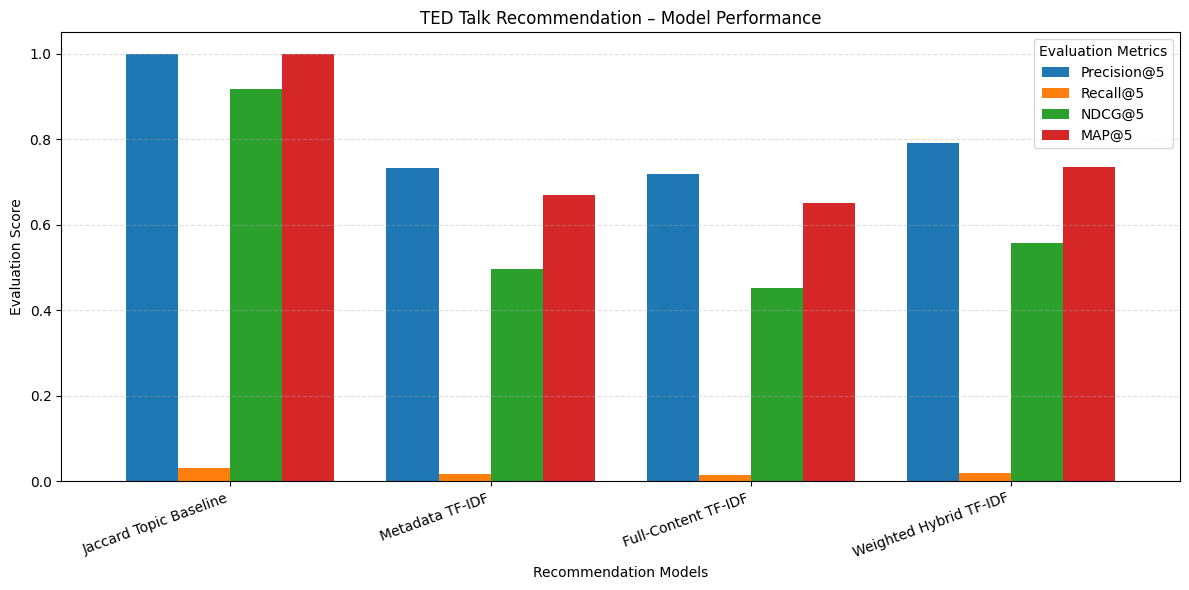

In [ ]:
metric_columns = [
    "Precision@5",
    "Recall@5",
    "NDCG@5",
    "MAP@5"
]

plot_df = evaluation_df.set_index("Model")[metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("TED Talk Recommendation – Model Performance")
plt.xlabel("Recommendation Models")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("model_performance_comparison.png", dpi=300)
plt.show()

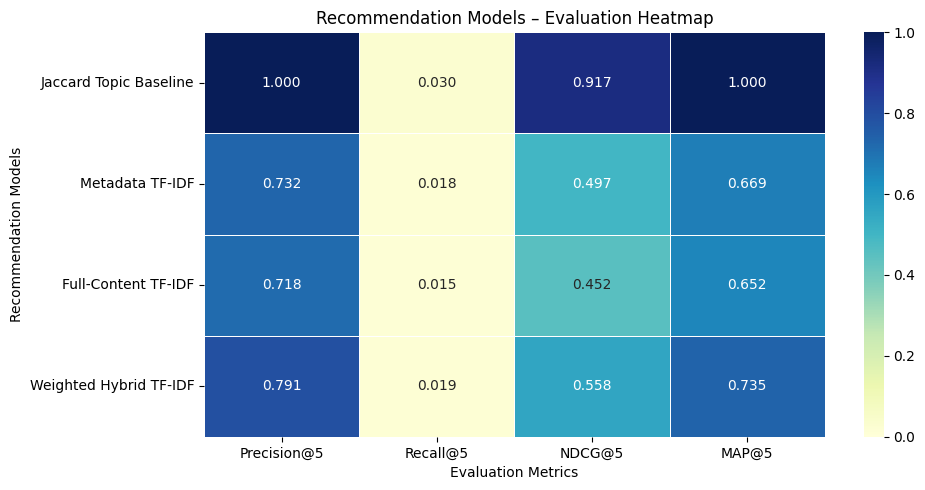

In [ ]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    plot_df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Recommendation Models – Evaluation Heatmap")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Recommendation Models")

plt.tight_layout()
plt.savefig("model_evaluation_heatmap.png", dpi=300)
plt.show()

In [ ]:
# Equal importance to all four metrics
evaluation_df["Overall Score"] = (
    evaluation_df["Precision@5"] +
    evaluation_df["Recall@5"] +
    evaluation_df["NDCG@5"] +
    evaluation_df["MAP@5"]
) / 4

evaluation_df = evaluation_df.sort_values(
    by="Overall Score",
    ascending=False
).reset_index(drop=True)

display(
    evaluation_df.style.format({
        "Precision@5": "{:.4f}",
        "Recall@5": "{:.4f}",
        "NDCG@5": "{:.4f}",
        "MAP@5": "{:.4f}",
        "Overall Score": "{:.4f}"
    })
)

best_model = evaluation_df.iloc[0]["Model"]

print("Selected model:", best_model)
print(
    "Overall evaluation score:",
    round(evaluation_df.iloc[0]["Overall Score"], 4)
)

,Model,Precision@5,Recall@5,NDCG@5,MAP@5,Overall Score
0,Jaccard Topic Baseline,1.0000,0.0299,0.9165,1.0000,0.7366
1,Weighted Hybrid TF-IDF,0.7912,0.0191,0.5575,0.7351,0.5257
2,Metadata TF-IDF,0.7320,0.0176,0.4971,0.6691,0.4790
3,Full-Content TF-IDF,0.7176,0.0150,0.4517,0.6518,0.4590


Selected model: Jaccard Topic Baseline
Overall evaluation score: 0.7366


In [ ]:
# Save evaluation table
evaluation_df.to_csv(
    "ted_recommendation_evaluation.csv",
    index=False
)

# Save detailed evaluation plots
print("Evaluation reports saved successfully!")

print("\nFiles generated:")
print("1. ted_recommendation_evaluation.csv")
print("2. model_performance_comparison.png")
print("3. model_evaluation_heatmap.png")

Evaluation reports saved successfully!

Files generated:
1. ted_recommendation_evaluation.csv
2. model_performance_comparison.png
3. model_evaluation_heatmap.png
